<a href="https://colab.research.google.com/github/Ayushmaantiwari/Semantic_Communication/blob/main/Semantic_Communication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1 — Runtime mode and experiment configuration
MODE = "QUICK"   # Change to "FULL" for final experiments

if MODE.upper() == "QUICK":
    TRAIN_SENTENCE_LIMIT = 6000
    TEST_SENTENCE_LIMIT = 400
    MAX_VOCAB = 8000
    MAX_LEN = 24
    BATCH_SIZE = 96
    EPOCHS = 2
    TRAIN_CHANNELS = 500
    EVAL_SENTENCES = 80
    MILP_DATASET_SIZE = 80
    DNN_EPOCHS = 25
else:
    TRAIN_SENTENCE_LIMIT = 20000
    TEST_SENTENCE_LIMIT = 2000
    MAX_VOCAB = 15000
    MAX_LEN = 32
    BATCH_SIZE = 128
    EPOCHS = 18
    TRAIN_CHANNELS = 3000
    EVAL_SENTENCES = 500
    MILP_DATASET_SIZE = 500
    DNN_EPOCHS = 100

SEED = 42
K_VALUES = [1, 2, 4, 8]
SNR_GRID = [-6, -3, 0, 3, 6, 9, 12, 15, 18]
U, N_RB = 8, 16
RB_BW = 180e3
BS_POWER_DBM = 30.0
CELL_RADIUS_M = 500.0
MIN_DISTANCE_M = 35.0
SEMANTIC_THRESHOLD = 0.90
MIN_USER_SEMANTIC_RATE = 2000.0
NOISE_FIGURE_DB = 7.0
PATHLOSS_1M_DB = 38.0       # Explicit assumption; replace with Exercise 1 value if different
PATHLOSS_EXPONENT = 3.5     # Explicit assumption; replace with Exercise 1 value if different
SHADOWING_STD_DB = 8.0      # Explicit assumption; replace with Exercise 1 value if different

print("Mode:", MODE)
print("GPU will be selected automatically in the next cell.")

Mode: QUICK
GPU will be selected automatically in the next cell.


In [2]:
# CELL 2 — Install dependencies (run once in Colab)
!pip -q install nltk sentence-transformers scipy pandas matplotlib seaborn

In [3]:
# CELL 3 — Imports, reproducibility and device
import os, re, math, json, time, random, heapq, zipfile, warnings
from collections import Counter
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix, csr_matrix

import nltk
from nltk.corpus import brown
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")
os.makedirs("/content/semantic_comm_outputs/figures", exist_ok=True)
os.makedirs("/content/semantic_comm_outputs/models", exist_ok=True)
os.makedirs("/content/semantic_comm_outputs/tables", exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1+cu130
Device: cuda


In [4]:
# CELL 4 — Dataset download, cleaning, split and vocabulary
nltk.download("brown", quiet=True)
nltk.download("punkt", quiet=True)

def normalize_sentence(tokens):
    words = [re.sub(r"[^a-z0-9']", "", str(w).lower()) for w in tokens]
    words = [w for w in words if w and len(w) < 25]
    return words

raw_sentences = []
for sent in brown.sents():
    words = normalize_sentence(sent)
    if 4 <= len(words) <= MAX_LEN:
        raw_sentences.append(" ".join(words))

# Deterministic shuffle and split; Brown is a fallback corpus if Exercise 1's corpus is not supplied.
rng = np.random.default_rng(SEED)
rng.shuffle(raw_sentences)
needed = TRAIN_SENTENCE_LIMIT + TEST_SENTENCE_LIMIT
if len(raw_sentences) < needed:
    raise RuntimeError(f"Brown corpus has only {len(raw_sentences)} usable sentences; reduce limits or provide the Exercise 1 corpus.")

train_sentences = raw_sentences[:TRAIN_SENTENCE_LIMIT]
test_sentences = raw_sentences[TRAIN_SENTENCE_LIMIT:needed]

PAD, UNK, BOS, EOS = "<pad>", "<unk>", "<bos>", "<eos>"
word_counts = Counter(w for s in train_sentences for w in s.split())
itos = [PAD, UNK, BOS, EOS] + [w for w, _ in word_counts.most_common(MAX_VOCAB-4)]
stoi = {w:i for i,w in enumerate(itos)}
PAD_ID, UNK_ID, BOS_ID, EOS_ID = [stoi[x] for x in (PAD, UNK, BOS, EOS)]

def encode_sentence(sentence):
    ids = [BOS_ID] + [stoi.get(w, UNK_ID) for w in sentence.split()] + [EOS_ID]
    ids = ids[:MAX_LEN]
    return ids + [PAD_ID] * (MAX_LEN-len(ids))

def decode_ids(ids):
    words = []
    for idx in ids:
        idx = int(idx)
        if idx == EOS_ID:
            break
        if idx not in (PAD_ID, BOS_ID):
            words.append(itos[idx] if 0 <= idx < len(itos) else UNK)
    return " ".join(words)

X_train = np.asarray([encode_sentence(s) for s in train_sentences], dtype=np.int64)
X_test = np.asarray([encode_sentence(s) for s in test_sentences], dtype=np.int64)

all_words = [w for s in train_sentences for w in s.split()]
word_freq = np.array(list(Counter(all_words).values()), dtype=float)
p = word_freq / word_freq.sum()
word_entropy_bits = float(-(p*np.log2(p)).sum())
mean_sentence_words = float(np.mean([len(s.split()) for s in train_sentences]))

corpus_stats = pd.DataFrame({
    "Metric": ["Training sentences", "Testing sentences", "Vocabulary size",
               "Average sentence length (words)", "Word entropy (bits/word)"],
    "Value": [len(train_sentences), len(test_sentences), len(itos),
              mean_sentence_words, word_entropy_bits]
})
display(corpus_stats)
corpus_stats.to_csv("/content/semantic_comm_outputs/tables/corpus_statistics.csv", index=False)
print("Dataset: NLTK Brown corpus (fallback; replace with Exercise 1 corpus if available).")

,Metric,Value
0,Training sentences,6000.000000
1,Testing sentences,400.000000
2,Vocabulary size,8000.000000
3,Average sentence length (words),13.462500
4,Word entropy (bits/word),10.325637


Dataset: NLTK Brown corpus (fallback; replace with Exercise 1 corpus if available).


Loading sentence embedding model once...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,Reference,Candidate,Pair type,BLEU,Word_accuracy,Embedding_similarity
0,the train arrived at the station,the train arrived at the station,exact,1.000000,1.000000,1.000000
1,the boy is happy today,the child is joyful today,synonym,0.070711,0.600000,0.688306
2,the dog chased the cat,the cat chased the dog,word order,0.188030,0.600000,0.990885
3,the meeting is on monday,the meeting is on tuesday,wrong day,0.668740,0.800000,0.943977
4,the city is paris,the city is london,wrong place,0.397635,0.750000,0.528948
5,the temperature is 20 degrees,the temperature is 30 degrees,wrong number,0.285744,0.800000,0.640604
6,wireless networks transmit information,wireless systems send information,synonym,0.095544,0.500000,0.890255
7,the engineer repaired the machine,the technician fixed the machine,synonym,0.125743,0.600000,0.803601
8,the sky is blue,the blue sky is,word order,0.202052,0.250000,0.971275
9,the doctor treated the patient,the patient treated the doctor,word order,0.188030,0.600000,0.991215


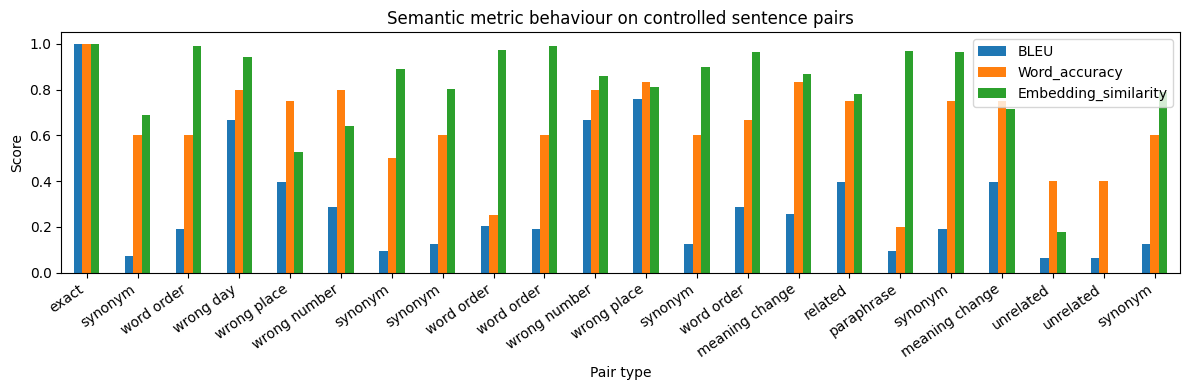

In [5]:
# CELL 5 — Sentence metrics and sentence-pair semantic evaluation
print("Loading sentence embedding model once...")
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=str(DEVICE))

smooth = SmoothingFunction().method1

def bleu_metric(reference, candidate):
    ref = reference.split()
    cand = candidate.split()
    if not ref or not cand:
        return 0.0
    return float(sentence_bleu([ref], cand, smoothing_function=smooth))

def word_accuracy(reference, candidate):
    a, b = reference.split(), candidate.split()
    if not a:
        return float(not b)
    # Position-wise accuracy; extra/missing words count as errors.
    return sum(i < len(b) and a[i] == b[i] for i in range(len(a))) / len(a)

def semantic_similarity(texts_a, texts_b):
    ea = embedder.encode(texts_a, convert_to_numpy=True, normalize_embeddings=True,
                         show_progress_bar=False)
    eb = embedder.encode(texts_b, convert_to_numpy=True, normalize_embeddings=True,
                         show_progress_bar=False)
    return np.sum(ea*eb, axis=1)

pair_examples = [
("the train arrived at the station", "the train arrived at the station", "exact"),
("the boy is happy today", "the child is joyful today", "synonym"),
("the dog chased the cat", "the cat chased the dog", "word order"),
("the meeting is on monday", "the meeting is on tuesday", "wrong day"),
("the city is paris", "the city is london", "wrong place"),
("the temperature is 20 degrees", "the temperature is 30 degrees", "wrong number"),
("wireless networks transmit information", "wireless systems send information", "synonym"),
("the engineer repaired the machine", "the technician fixed the machine", "synonym"),
("the sky is blue", "the blue sky is", "word order"),
("the doctor treated the patient", "the patient treated the doctor", "word order"),
("the bus leaves at eight", "the bus leaves at nine", "wrong number"),
("the capital of france is paris", "the capital of france is rome", "wrong place"),
("water is essential for life", "water is necessary for living", "synonym"),
("the phone is on the table", "the table is on the phone", "word order"),
("the company opened a new office", "the company closed a new office", "meaning change"),
("machine learning improves prediction", "deep learning improves prediction", "related"),
("the child reads a book", "a child is reading a book", "paraphrase"),
("the airplane landed safely", "the aircraft landed safely", "synonym"),
("the farmer grows wheat", "the farmer grows rice", "meaning change"),
("the ocean contains salt water", "the galaxy contains many stars", "unrelated"),
("the network has low latency", "the garden has colorful flowers", "unrelated"),
("the server processes user requests", "the computer handles user requests", "synonym")
]
pair_df = pd.DataFrame(pair_examples, columns=["Reference", "Candidate", "Pair type"])
pair_df["BLEU"] = [bleu_metric(a,b) for a,b,_ in pair_examples]
pair_df["Word_accuracy"] = [word_accuracy(a,b) for a,b,_ in pair_examples]
pair_df["Embedding_similarity"] = semantic_similarity(pair_df.Reference.tolist(), pair_df.Candidate.tolist())
display(pair_df)
pair_df.to_csv("/content/semantic_comm_outputs/tables/sentence_pair_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(12,4))
pair_df.set_index("Pair type")[["BLEU","Word_accuracy","Embedding_similarity"]].plot(kind="bar", ax=ax)
ax.set_title("Semantic metric behaviour on controlled sentence pairs")
ax.set_ylabel("Score")
ax.set_ylim(0,1.05)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("/content/semantic_comm_outputs/figures/sentence_pair_metrics.png", dpi=160)
plt.show()

In [6]:
# CELL 6 — Conventional baseline: shared Huffman codebooks, convolutional coding and square QAM
# Rate-1/2 convolutional code: constraint length 3, generators (7,5).
# For rate 3/4, puncturing pattern [1,1,1,0,0,1] is applied to the rate-1/2 output.

def build_huffman_code(symbols):
    freq = Counter(symbols)
    if len(freq) == 1:
        only = next(iter(freq))
        return {only: "0"}
    heap = []
    serial = 0
    for sym, count in freq.items():
        heapq.heappush(heap, (count, serial, sym))
        serial += 1
    while len(heap) > 1:
        f1, _, a = heapq.heappop(heap)
        f2, _, b = heapq.heappop(heap)
        heapq.heappush(heap, (f1+f2, serial, (a,b)))
        serial += 1
    codes = {}
    def walk(node, prefix):
        if not isinstance(node, tuple):
            codes[node] = prefix or "0"
        else:
            walk(node[0], prefix+"0")
            walk(node[1], prefix+"1")
    walk(heap[0][2], "")
    return codes

def huff_decode(bitstr, codebook):
    inv = {v:k for k,v in codebook.items()}
    out, cur = [], ""
    for bit in bitstr:
        cur += bit
        if cur in inv:
            out.append(inv[cur]); cur = ""
    return out

char_code = build_huffman_code([ch for s in train_sentences for ch in s])
word_code = build_huffman_code([w for s in train_sentences for w in s.split()])
PUNCTURE = [1,1,1,0,0,1]

def conv_encode(bits, rate="1/2"):
    b = [int(x) for x in bits] + [0,0]
    state = [0,0]
    out = []
    for bit in b:
        r = [bit] + state
        pair = [r[0]^r[1]^r[2], r[0]^r[2]]
        out.extend(pair)
        state = r[:2]
    if rate == "3/4":
        out = [v for i,v in enumerate(out) if PUNCTURE[i % len(PUNCTURE)]]
    return np.asarray(out, dtype=np.uint8), len(b)

def conv_viterbi_decode(rx, steps, rate="1/2"):
    # Expand punctured observations into pairs; erased bits have zero branch cost.
    if rate == "1/2":
        pairs = rx.reshape(-1,2)
        mask = np.ones_like(pairs, dtype=bool)
    else:
        full_len = steps*2
        expanded = np.zeros(full_len, dtype=np.uint8)
        mask = np.zeros(full_len, dtype=bool)
        j = 0
        for i in range(full_len):
            if PUNCTURE[i % len(PUNCTURE)]:
                expanded[i] = rx[j]; mask[i] = True; j += 1
        pairs = expanded.reshape(-1,2)
        mask = mask.reshape(-1,2)
    metrics = np.full(4, 1e9); metrics[0] = 0
    paths = [[] for _ in range(4)]
    for t, obs in enumerate(pairs):
        newm = np.full(4, 1e9); newp = [[] for _ in range(4)]
        for st in range(4):
            if metrics[st] >= 1e8: continue
            s1, s0 = (st>>1)&1, st&1
            for bit in (0,1):
                r0,r1,r2 = bit,s1,s0
                out = np.array([r0^r1^r2, r0^r2], dtype=np.uint8)
                ns = ((bit<<1)|s1)
                cost = int(np.sum((out != obs) & mask[t]))
                if metrics[st]+cost < newm[ns]:
                    newm[ns] = metrics[st]+cost
                    newp[ns] = paths[st]+[bit]
        metrics, paths = newm, newp
    decoded = paths[int(np.argmin(metrics))]
    return "".join(map(str, decoded[:steps-2]))

def gray_to_binary(g):
    b = g
    while g:
        g >>= 1
        b ^= g
    return b

def qam_constellation(M):
    m = int(round(math.sqrt(M)))
    bits_axis = int(math.log2(m))
    points = []
    for idx in range(M):
        bits = format(idx, f"0{int(math.log2(M))}b")
        ibits, qbits = bits[:bits_axis], bits[bits_axis:]
        gi, gq = int(ibits,2), int(qbits,2)
        ii, qq = gray_to_binary(gi), gray_to_binary(gq)
        I, Q = 2*ii-(m-1), 2*qq-(m-1)
        points.append((complex(I,Q), bits))
    arr = np.array([p[0] for p in points], dtype=np.complex128)
    arr /= np.sqrt(np.mean(np.abs(arr)**2))
    return arr, [p[1] for p in points]

def qam_mod(bits, M):
    const, labels = qam_constellation(M)
    k = int(math.log2(M))
    pad = (-len(bits)) % k
    bits = bits + "0"*pad
    lookup = {lab: const[i] for i,lab in enumerate(labels)}
    return np.asarray([lookup[bits[i:i+k]] for i in range(0,len(bits),k)]), pad

def qam_demod(symbols, M):
    const, labels = qam_constellation(M)
    out = []
    for z in symbols:
        out.append(labels[int(np.argmin(np.abs(z-const)))])
    return "".join(out)

def transmit_bits(bits, M, snr_db):
    tx, pad = qam_mod(bits, M)
    h = (np.random.randn(len(tx)) + 1j*np.random.randn(len(tx))) / np.sqrt(2)
    rx_power = np.mean(np.abs(tx*h)**2)
    snr = 10**(snr_db/10)
    noise_var = rx_power / snr
    noise = np.sqrt(noise_var/2)*(np.random.randn(len(tx))+1j*np.random.randn(len(tx)))
    rx = (tx*h+noise) / np.where(np.abs(h)<1e-8, 1e-8+0j, h)
    return qam_demod(rx, M)[:-pad] if pad else qam_demod(rx, M), len(tx)

def conventional_once(sentence, mode, M, rate, snr_db):
    if mode == "character":
        seq = list(sentence)
        cb = char_code
    else:
        seq = sentence.split()
        cb = word_code
    # Unknown symbols are represented by a shared UNK symbol.
    unk_sym = " " if mode == "character" else "<unk>"
    bits = "".join(cb.get(x, cb.get(unk_sym, next(iter(cb.values())))) for x in seq)
    coded, steps = conv_encode(bits, rate)
    rx_bits, n_channel_uses = transmit_bits("".join(map(str,coded)), M, snr_db)
    rx_coded = np.fromiter((int(x) for x in rx_bits), dtype=np.uint8)
    # QAM demodulated padding is removed by transmit_bits; trim any remaining excess.
    needed = len(coded)
    rx_coded = rx_coded[:needed]
    if rate == "3/4":
        decoded = conv_viterbi_decode(rx_coded, steps, rate)
    else:
        decoded = conv_viterbi_decode(rx_coded, steps, rate)
    symbols = huff_decode(decoded, cb)
    recovered = "".join(symbols) if mode == "character" else " ".join(symbols)
    return recovered, n_channel_uses

print("Huffman codebooks:", len(char_code), "characters;", len(word_code), "words")

Huffman codebooks: 38 characters; 13564 words


,SNR_dB,Coding,MCS,BLEU,Word_accuracy,Similarity,Channel_uses
0,-6,character,16-QAM 1/2,0.000980,0.000833,0.065348,158.8750
1,-6,character,64-QAM 3/4,0.000586,0.000625,0.065866,70.9125
2,-6,character,QPSK 1/2,0.000633,0.001667,0.065654,317.1500
3,-6,word,16-QAM 1/2,0.009079,0.008789,0.090618,64.0000
4,-6,word,64-QAM 3/4,0.010804,0.013164,0.096411,28.7750
5,-6,word,QPSK 1/2,0.011848,0.016093,0.088341,127.5250
6,-3,character,16-QAM 1/2,0.000839,0.000000,0.068648,158.8750
7,-3,character,64-QAM 3/4,0.000232,0.000000,0.065444,70.9125
8,-3,character,QPSK 1/2,0.002528,0.008589,0.078375,317.1500
9,-3,word,16-QAM 1/2,0.009387,0.010392,0.076299,64.0000


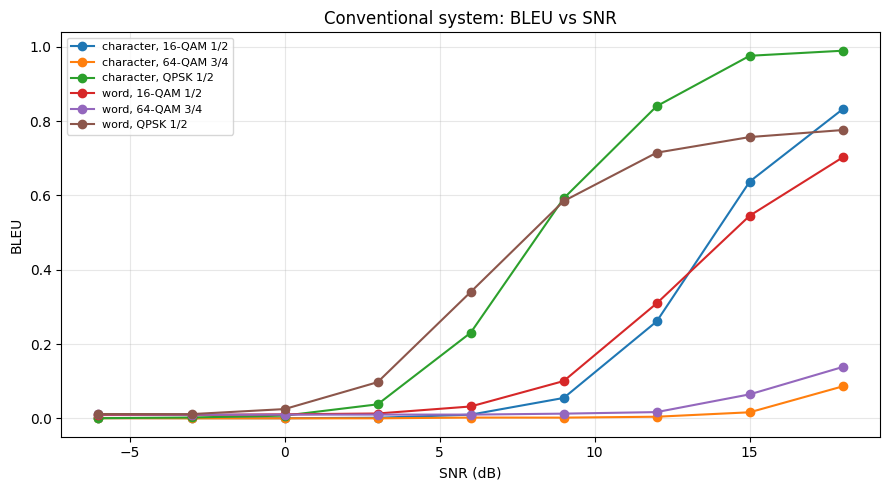

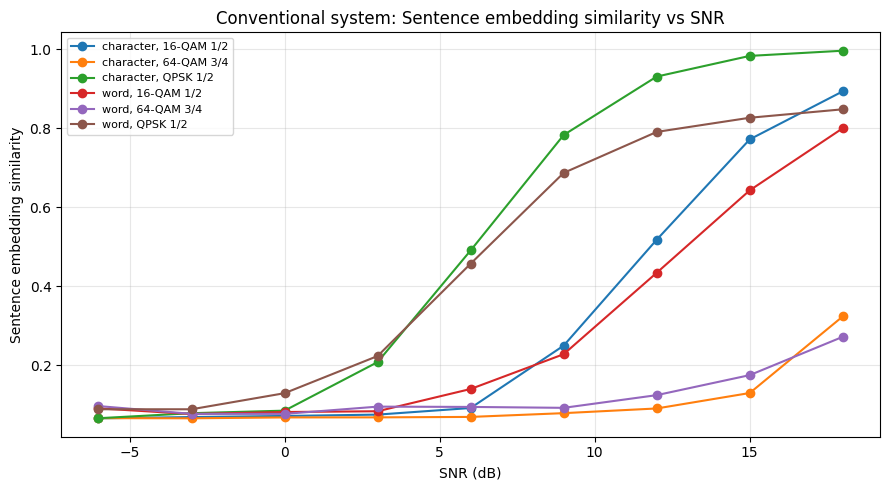

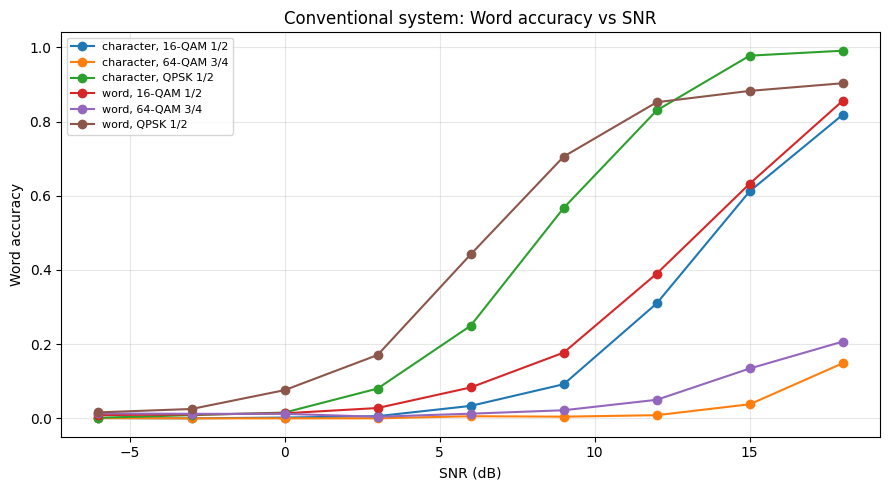

In [7]:
# CELL 7 — Conventional AMC evaluation (actual decoded text)
MCS_LIST = [
    ("QPSK 1/2", 4, "1/2"),
    ("16-QAM 1/2", 16, "1/2"),
    ("64-QAM 3/4", 64, "3/4")
]
CONV_SENTENCES = test_sentences[:EVAL_SENTENCES]
conv_records = []

for snr_db in SNR_GRID:
    for coding_mode in ["character", "word"]:
        for mcs_name, M, rate in MCS_LIST:
            for sent in CONV_SENTENCES:
                recovered, uses = conventional_once(sent, coding_mode, M, rate, snr_db)
                conv_records.append({
                    "SNR_dB": snr_db, "Coding": coding_mode, "MCS": mcs_name,
                    "Reference": sent, "Recovered": recovered,
                    "BLEU": bleu_metric(sent, recovered),
                    "Word_accuracy": word_accuracy(sent, recovered),
                    "Channel_uses": uses
                })

conv_df = pd.DataFrame(conv_records)
# Embedding similarity is batched for efficiency.
conv_df["Similarity"] = semantic_similarity(conv_df.Reference.tolist(), conv_df.Recovered.tolist())
conv_summary = (conv_df.groupby(["SNR_dB","Coding","MCS"])
                [["BLEU","Word_accuracy","Similarity","Channel_uses"]].mean().reset_index())
display(conv_summary.head(12))
conv_summary.to_csv("/content/semantic_comm_outputs/tables/conventional_summary.csv", index=False)

for metric, ylabel in [("BLEU","BLEU"),("Similarity","Sentence embedding similarity"),("Word_accuracy","Word accuracy")]:
    plt.figure(figsize=(9,5))
    for (coding,mcs), d in conv_summary.groupby(["Coding","MCS"]):
        plt.plot(d.SNR_dB, d[metric], marker="o", label=f"{coding}, {mcs}")
    plt.xlabel("SNR (dB)"); plt.ylabel(ylabel); plt.title(f"Conventional system: {ylabel} vs SNR")
    plt.grid(True, alpha=.3); plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"/content/semantic_comm_outputs/figures/conventional_{metric.lower()}.png", dpi=160)
    plt.show()

In [8]:

# CELL 8 — Dataset wrapper and corrected Transformer semantic transceiver

class SentenceDataset(Dataset):
    def __init__(self, array):
        self.x = torch.tensor(array, dtype=torch.long)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i]


train_loader = DataLoader(
    SentenceDataset(X_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    SentenceDataset(X_test[:min(500, len(X_test))]),
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ------------------------------------------------
# Positional Encoding
# ------------------------------------------------

class PositionalEncoding(nn.Module):

    def __init__(self, d_model=128, max_len=MAX_LEN):

        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            0, max_len
        ).unsqueeze(1).float()

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)

        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer(
            "pe",
            pe.unsqueeze(0)
        )

    def forward(self, x):

        seq_len = x.size(1)

        return x + self.pe[:, :seq_len, :]


# ------------------------------------------------
# Semantic Communication Transceiver
# ------------------------------------------------

class SemanticTransceiver(nn.Module):

    def __init__(
        self,
        vocab_size,
        K,
        d_model=128,
        heads=4,
        layers=2
    ):

        super().__init__()

        self.K = K
        self.d_model = d_model

        # Word embedding
        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_ID
        )

        # Positional encoding
        self.pos = PositionalEncoding(
            d_model=d_model,
            max_len=MAX_LEN
        )

        # Transformer semantic encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=heads,
            dim_feedforward=4*d_model,
            batch_first=True,
            norm_first=True
        )

        self.semantic_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=layers
        )

        # Dense channel encoder
        self.channel_encoder = nn.Sequential(
            nn.Linear(d_model, 2*K),
            nn.Tanh()
        )

        # Dense channel decoder
        self.channel_decoder = nn.Sequential(
            nn.Linear(2*K, d_model),
            nn.LayerNorm(d_model),
            nn.GELU()
        )

        # Transformer semantic decoder
        decoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=heads,
            dim_feedforward=4*d_model,
            batch_first=True,
            norm_first=True
        )

        self.semantic_decoder = nn.TransformerEncoder(
            decoder_layer,
            num_layers=layers
        )

        # Vocabulary prediction
        self.output = nn.Linear(
            d_model,
            vocab_size
        )


    # ------------------------------------------------
    # Forward propagation
    # ------------------------------------------------

    def forward(
        self,
        token_ids,
        snr_db=None,
        channel="awgn"
    ):

        batch_size, seq_len = token_ids.shape

        # Padding mask
        pad_mask = token_ids.eq(PAD_ID)

        # 1. Semantic encoding
        embedded = self.embedding(token_ids)

        embedded = self.pos(embedded)

        semantic_features = self.semantic_encoder(
            embedded,
            src_key_padding_mask=pad_mask
        )

        # 2. Dense channel encoding
        raw = self.channel_encoder(
            semantic_features
        )

        raw = raw.reshape(
            batch_size,
            seq_len,
            self.K,
            2
        )

        # 3. Average transmit power normalization
        power = (
            raw[..., 0]**2 + raw[..., 1]**2
        ).mean(
            dim=(1, 2),
            keepdim=True
        ).clamp_min(1e-8)

        raw = raw / torch.sqrt(power).unsqueeze(-1)

        # 4. Convert to complex channel symbols
        tx = torch.complex(
            raw[..., 0],
            raw[..., 1]
        )

        # 5. Random SNR during training
        if snr_db is None:

            snr_db = torch.empty(
                batch_size,
                device=token_ids.device
            ).uniform_(-6, 18)

        snr = torch.pow(
            10.0,
            snr_db.view(-1, 1, 1) / 10.0
        )

        noise_var = 1.0 / snr

        # 6. Wireless channel
        if channel.lower() == "rayleigh":

            h = torch.complex(
                torch.randn_like(tx.real),
                torch.randn_like(tx.real)
            ) / math.sqrt(2)

        else:

            h = torch.ones_like(tx)

        noise = torch.complex(
            torch.randn_like(tx.real),
            torch.randn_like(tx.real)
        ) * torch.sqrt(noise_var / 2)

        rx = h * tx + noise

        # 7. Zero-forcing equalization
        zf = (
            rx * torch.conj(h)
        ) / (
            h.abs().square() + 1e-6
        )

        # 8. Separate real and imaginary components
        features = torch.stack(
            [zf.real, zf.imag],
            dim=-1
        )

        features = features.reshape(
            batch_size,
            seq_len,
            2*self.K
        )

        # 9. Dense channel decoding
        # IMPORTANT: Do not apply mean(dim=2) here.
        # The decoder must preserve the 128-dimensional embedding.
        decoded_features = self.channel_decoder(
            features
        )

        # 10. Transformer semantic decoding
        decoded_features = self.pos(
            decoded_features
        )

        decoded_features = self.semantic_decoder(
            decoded_features,
            src_key_padding_mask=pad_mask
        )

        # 11. Predict original vocabulary tokens
        logits = self.output(
            decoded_features
        )

        return logits


# ------------------------------------------------
# Model dimension validation
# ------------------------------------------------

for K in K_VALUES:

    test_model = SemanticTransceiver(
        vocab_size=len(itos),
        K=K
    ).to(DEVICE)

    dummy_input = torch.randint(
        0,
        len(itos),
        (2, MAX_LEN),
        device=DEVICE
    )

    dummy_snr = torch.tensor(
        [6.0, 12.0],
        device=DEVICE
    )

    with torch.no_grad():

        dummy_output = test_model(
            dummy_input,
            dummy_snr,
            channel="awgn"
        )

    assert dummy_output.shape == (
        2,
        MAX_LEN,
        len(itos)
    ), f"Dimension mismatch for K={K}"

    print(
        f"K={K} | Input: {tuple(dummy_input.shape)} "
        f"| Output: {tuple(dummy_output.shape)}"
    )

    del test_model, dummy_input, dummy_output

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print("\nSemantic transceiver architecture validated successfully.")


K=1 | Input: (2, 24) | Output: (2, 24, 8000)
K=2 | Input: (2, 24) | Output: (2, 24, 8000)
K=4 | Input: (2, 24) | Output: (2, 24, 8000)
K=8 | Input: (2, 24) | Output: (2, 24, 8000)

Semantic transceiver architecture validated successfully.


K=1 | epoch 1/2 | train=7.0320 | val=5.0137
K=1 | epoch 2/2 | train=5.2910 | val=4.5407
K=2 | epoch 1/2 | train=6.7630 | val=4.7594
K=2 | epoch 2/2 | train=4.9540 | val=4.1439
K=4 | epoch 1/2 | train=6.5880 | val=4.3473
K=4 | epoch 2/2 | train=4.5703 | val=3.6084
K=8 | epoch 1/2 | train=6.6937 | val=4.3099
K=8 | epoch 2/2 | train=4.3962 | val=3.2945


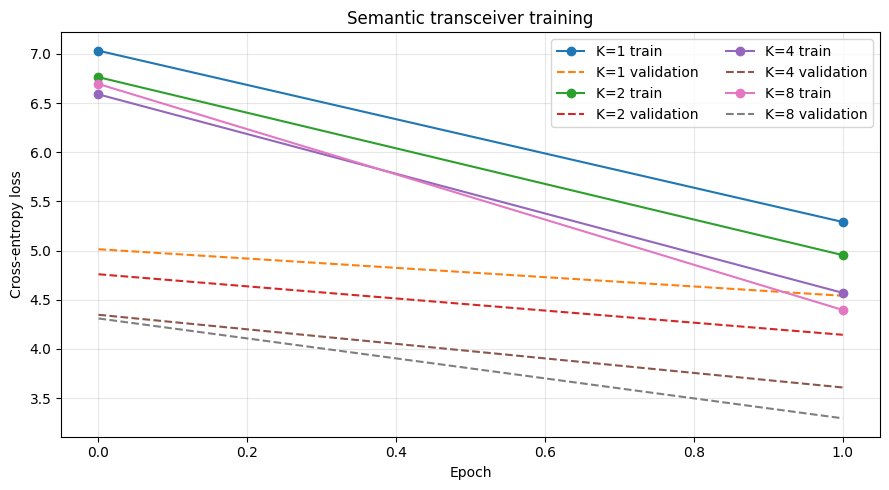

In [9]:
# CELL 9 — Train one semantic transceiver per K
def train_transceiver(K, epochs=EPOCHS):
    model = SemanticTransceiver(len(itos), K).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=2, factor=.5)
    train_hist, val_hist = [], []
    best_val = float("inf")
    best_state = None

    for epoch in range(epochs):
        model.train()
        losses = []
        for tokens in train_loader:
            tokens = tokens.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            snr_batch = torch.empty(tokens.size(0), device=DEVICE).uniform_(-6,18)
            logits = model(tokens, snr_batch, channel="awgn")
            loss = F.cross_entropy(logits.reshape(-1,len(itos)), tokens.reshape(-1),
                                   ignore_index=PAD_ID)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(loss.item())
        model.eval()
        vlosses = []
        with torch.no_grad():
            for tokens in val_loader:
                tokens = tokens.to(DEVICE)
                snr_batch = torch.empty(tokens.size(0), device=DEVICE).uniform_(-6,18)
                logits = model(tokens, snr_batch, channel="awgn")
                vlosses.append(F.cross_entropy(logits.reshape(-1,len(itos)), tokens.reshape(-1),
                                               ignore_index=PAD_ID).item())
        tr, va = float(np.mean(losses)), float(np.mean(vlosses))
        train_hist.append(tr); val_hist.append(va); scheduler.step(va)
        if va < best_val:
            best_val = va
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        print(f"K={K} | epoch {epoch+1}/{epochs} | train={tr:.4f} | val={va:.4f}")
    if best_state is not None:
        model.load_state_dict(best_state)
    torch.save({"K":K, "state_dict":model.state_dict(), "vocab":itos, "max_len":MAX_LEN},
               f"/content/semantic_comm_outputs/models/semantic_transceiver_K{K}.pt")
    return model, {"train":train_hist, "val":val_hist}

semantic_models, training_histories = {}, {}
for K in K_VALUES:
    semantic_models[K], training_histories[K] = train_transceiver(K)

plt.figure(figsize=(9,5))
for K in K_VALUES:
    plt.plot(training_histories[K]["train"], marker="o", label=f"K={K} train")
    plt.plot(training_histories[K]["val"], linestyle="--", label=f"K={K} validation")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title("Semantic transceiver training")
plt.grid(True, alpha=.3); plt.legend(ncol=2); plt.tight_layout()
plt.savefig("/content/semantic_comm_outputs/figures/semantic_training_loss.png", dpi=160)
plt.show()

,K,Channel,SNR_dB,BLEU,Word_accuracy,Similarity,Exact
0,1,awgn,-6,0.016640,0.044396,0.059558,0.0
1,1,awgn,-3,0.019133,0.041533,0.057991,0.0
2,1,awgn,0,0.017704,0.073374,0.056447,0.0
3,1,awgn,3,0.020047,0.071599,0.059982,0.0
4,1,awgn,6,0.021526,0.092810,0.062762,0.0
5,1,awgn,9,0.021842,0.092410,0.065167,0.0
6,1,awgn,12,0.021304,0.080409,0.065493,0.0
7,1,awgn,15,0.022460,0.093192,0.062079,0.0
8,1,awgn,18,0.021880,0.090364,0.061368,0.0
9,1,rayleigh,-6,0.013695,0.029531,0.061558,0.0


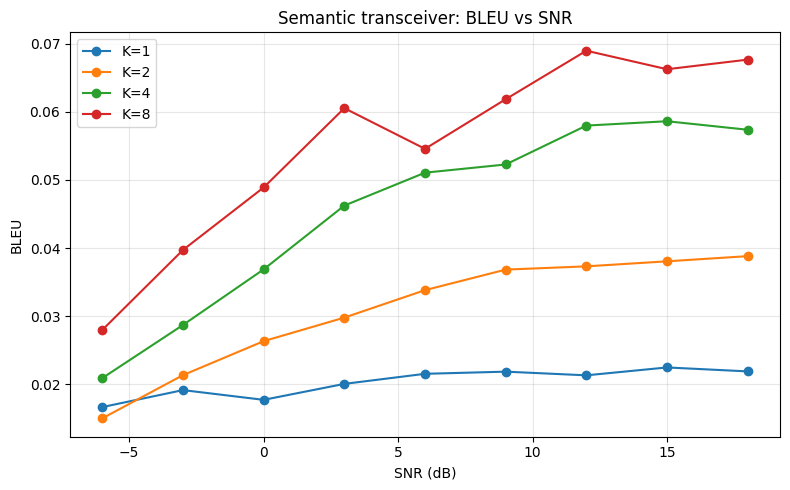

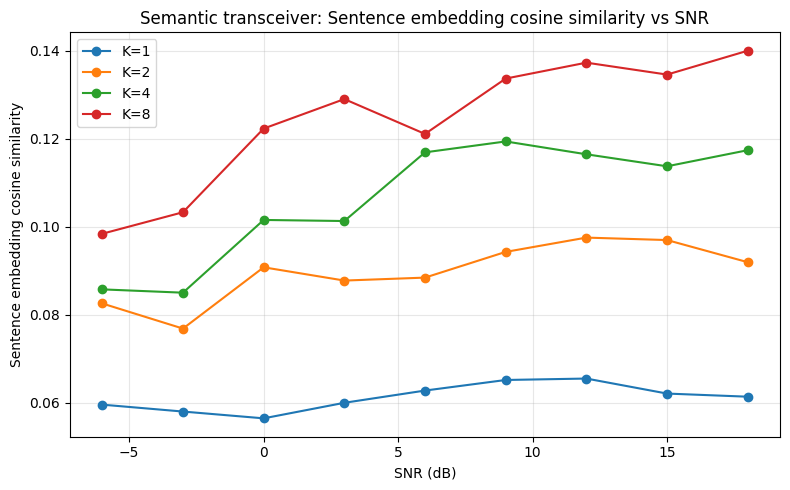

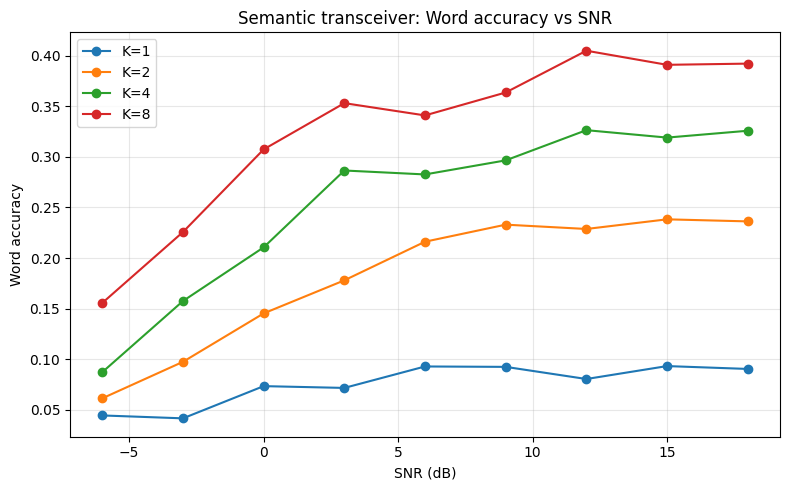

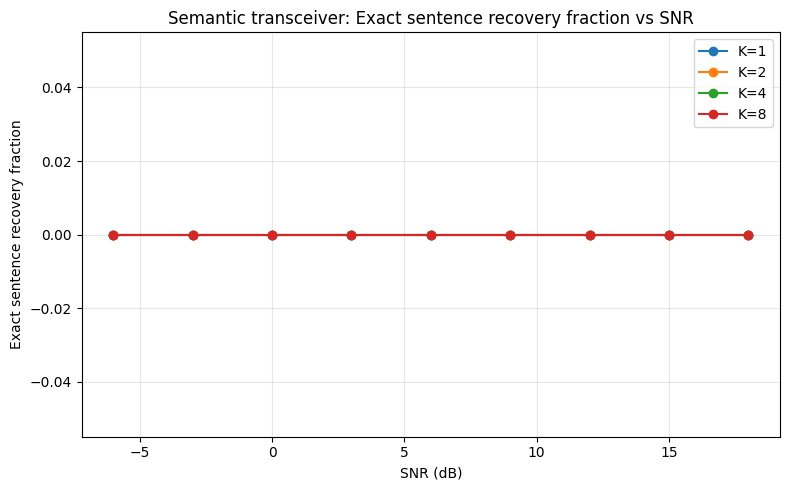

SNR_dB,-6,-3,0,3,6,9,12,15,18
K,,,,,,,,,
1,0.059558,0.057991,0.056447,0.059982,0.062762,0.065167,0.065493,0.062079,0.061368
2,0.082558,0.076850,0.090785,0.087769,0.088440,0.094286,0.097535,0.096977,0.091945
4,0.085765,0.085013,0.101548,0.101302,0.116917,0.119396,0.116474,0.113745,0.117406
8,0.098417,0.103302,0.122321,0.129024,0.121100,0.133685,0.137308,0.134596,0.140021


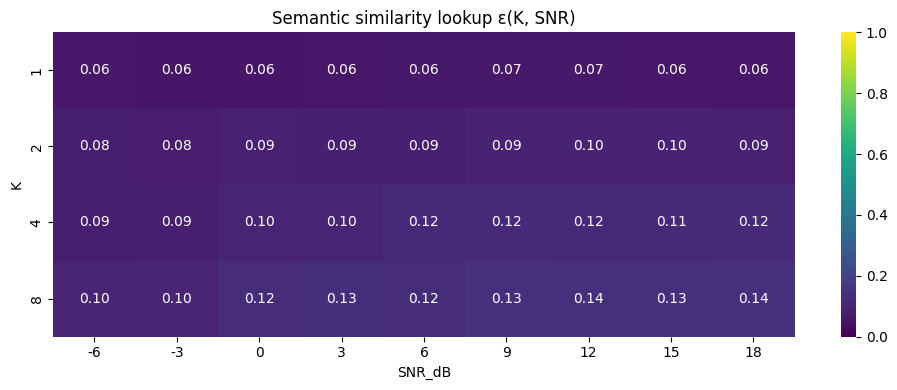

In [10]:
# CELL 10 — Semantic transceiver evaluation and lookup table
@torch.no_grad()
def semantic_reconstruct(model, sentences, snr_db, channel="awgn"):
    model.eval()
    arr = np.asarray([encode_sentence(s) for s in sentences], dtype=np.int64)
    x = torch.tensor(arr, dtype=torch.long, device=DEVICE)
    snr_vec = torch.full((len(x),), float(snr_db), device=DEVICE)
    logits = model(x, snr_vec, channel=channel)
    pred = logits.argmax(-1).cpu().numpy()
    return [decode_ids(row) for row in pred]

semantic_records = []
EVAL_SEM_SENTENCES = test_sentences[:EVAL_SENTENCES]
for K, model in semantic_models.items():
    for channel in ["awgn", "rayleigh"]:
        for snr_db in SNR_GRID:
            recovered = semantic_reconstruct(model, EVAL_SEM_SENTENCES, snr_db, channel)
            sims = semantic_similarity(EVAL_SEM_SENTENCES, recovered)
            for ref, rec, sim in zip(EVAL_SEM_SENTENCES, recovered, sims):
                semantic_records.append({
                    "K":K, "Channel":channel, "SNR_dB":snr_db,
                    "Reference":ref, "Recovered":rec,
                    "BLEU":bleu_metric(ref,rec),
                    "Word_accuracy":word_accuracy(ref,rec),
                    "Similarity":float(sim),
                    "Exact":int(ref.strip()==rec.strip())
                })

semantic_df = pd.DataFrame(semantic_records)
semantic_summary = (semantic_df.groupby(["K","Channel","SNR_dB"])
                    [["BLEU","Word_accuracy","Similarity","Exact"]].mean().reset_index())
display(semantic_summary.head(16))
semantic_summary.to_csv("/content/semantic_comm_outputs/tables/semantic_transceiver_summary.csv", index=False)

awgn_summary = semantic_summary[semantic_summary.Channel=="awgn"]
for metric, ylabel in [("BLEU","BLEU"),("Similarity","Sentence embedding cosine similarity"),
                       ("Word_accuracy","Word accuracy"),("Exact","Exact sentence recovery fraction")]:
    plt.figure(figsize=(8,5))
    for K,d in awgn_summary.groupby("K"):
        plt.plot(d.SNR_dB,d[metric],marker="o",label=f"K={K}")
    plt.xlabel("SNR (dB)"); plt.ylabel(ylabel); plt.title(f"Semantic transceiver: {ylabel} vs SNR")
    plt.grid(True,alpha=.3); plt.legend(); plt.tight_layout()
    plt.savefig(f"/content/semantic_comm_outputs/figures/semantic_{metric.lower()}.png",dpi=160)
    plt.show()

lookup_df = awgn_summary.pivot(index="K",columns="SNR_dB",values="Similarity")
display(lookup_df)
lookup_df.to_csv("/content/semantic_comm_outputs/tables/semantic_similarity_lookup.csv")
plt.figure(figsize=(10,4))
sns.heatmap(lookup_df,annot=True,fmt=".2f",vmin=0,vmax=1,cmap="viridis")
plt.title("Semantic similarity lookup ε(K, SNR)")
plt.tight_layout()
plt.savefig("/content/semantic_comm_outputs/figures/semantic_similarity_lookup.png",dpi=160)
plt.show()

,K,SNR_dB,Mean_similarity,Exact_fraction
0,1,0,0.034394,0.0
1,1,6,0.044700,0.0
2,1,12,0.036645,0.0
3,2,0,0.041771,0.0
4,2,6,0.061701,0.0
5,2,12,0.052180,0.0
6,4,0,0.049945,0.0
7,4,6,0.034946,0.0
8,4,12,0.048032,0.0
9,8,0,0.071514,0.0


,K,SNR_dB,Mean_similarity,Mean_channel_uses
0,1,0,0.068109,13.4625
1,1,6,0.062731,13.4625
2,1,12,0.059803,13.4625
3,2,0,0.082566,26.9250
4,2,6,0.087747,26.9250
5,2,12,0.087934,26.9250
6,4,0,0.095968,53.8500
7,4,6,0.112083,53.8500
8,4,12,0.116116,53.8500
9,8,0,0.119702,107.7000


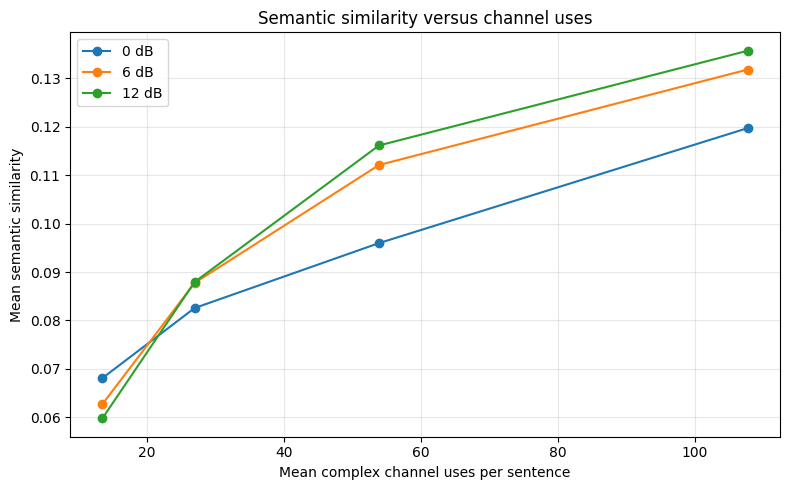

In [11]:
# CELL 11 — Knowledge-base mismatch and channel-use efficiency
# OOV words are mapped to UNK by the fixed training vocabulary.
mismatch_sentences = [
    "the quantum satellite schedules a lunar observation",
    "a biologist studies unusual marine organisms",
    "the spacecraft entered the distant orbit yesterday",
    "the algorithm predicts rainfall using sensor measurements",
    "the engineer repaired the autonomous underwater vehicle",
    "the network prioritizes emergency medical communication",
    "several researchers published a novel experimental result",
    "the spacecraft transmits telemetry through a narrow channel"
]
mismatch_rows = []
for K, model in semantic_models.items():
    for snr_db in [0,6,12]:
        rec = semantic_reconstruct(model, mismatch_sentences, snr_db, "awgn")
        sim = semantic_similarity(mismatch_sentences, rec)
        mismatch_rows.append({"K":K,"SNR_dB":snr_db,
                              "Mean_similarity":float(np.mean(sim)),
                              "Exact_fraction":float(np.mean([a==b for a,b in zip(mismatch_sentences,rec)]))})
mismatch_df = pd.DataFrame(mismatch_rows)
display(mismatch_df)
mismatch_df.to_csv("/content/semantic_comm_outputs/tables/knowledge_base_mismatch.csv",index=False)

# K complex symbols per word; sentence uses K times its number of words.
channel_use_rows = []
for K, model in semantic_models.items():
    for snr_db in [0,6,12]:
        rec = semantic_reconstruct(model,EVAL_SEM_SENTENCES,snr_db,"awgn")
        sim = semantic_similarity(EVAL_SEM_SENTENCES,rec)
        uses = np.array([K*len(s.split()) for s in EVAL_SEM_SENTENCES])
        channel_use_rows.append({"K":K,"SNR_dB":snr_db,
                                 "Mean_similarity":float(np.mean(sim)),
                                 "Mean_channel_uses":float(np.mean(uses))})
channel_use_df = pd.DataFrame(channel_use_rows)
display(channel_use_df)
channel_use_df.to_csv("/content/semantic_comm_outputs/tables/channel_use_efficiency.csv",index=False)

plt.figure(figsize=(8,5))
for snr,d in channel_use_df.groupby("SNR_dB"):
    plt.plot(d.Mean_channel_uses,d.Mean_similarity,marker="o",label=f"{snr} dB")
plt.xlabel("Mean complex channel uses per sentence")
plt.ylabel("Mean semantic similarity")
plt.title("Semantic similarity versus channel uses")
plt.grid(True,alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig("/content/semantic_comm_outputs/figures/similarity_vs_channel_uses.png",dpi=160)
plt.show()

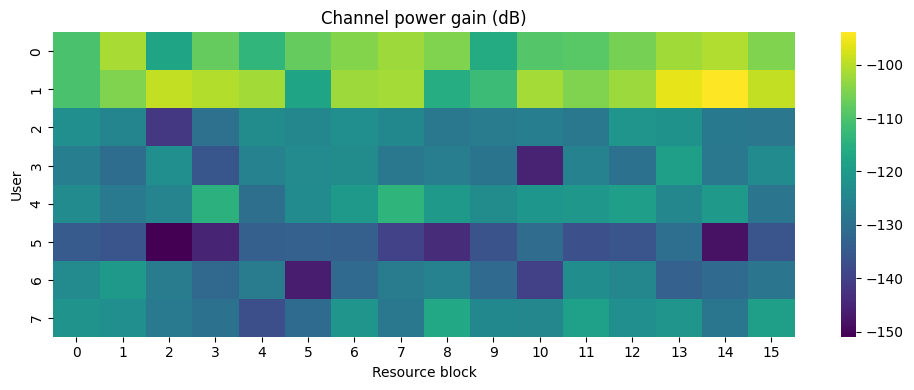

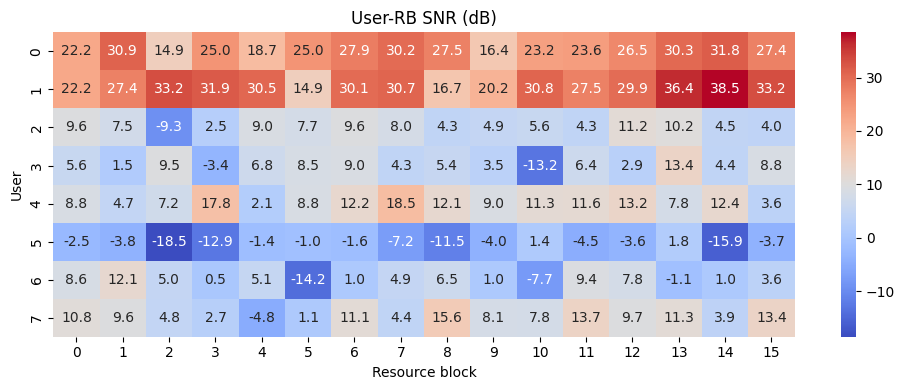

Rate tensor shape: (8, 16, 4)
User distances (m): [ 45.4  85.  336.2 481.7 393.2 457.3 141.  153. ]


In [12]:
# CELL 12 — Multi-user channel generation and semantic-rate matrices
def dbm_to_watt(dbm):
    return 10**((dbm-30)/10)

def generate_multiuser_channel(seed=None):
    rng = np.random.default_rng(seed)
    distances = rng.uniform(MIN_DISTANCE_M, CELL_RADIUS_M, size=U)
    shadow_db = rng.normal(0, SHADOWING_STD_DB, size=U)
    pathloss_db = PATHLOSS_1M_DB + 10*PATHLOSS_EXPONENT*np.log10(distances)
    large_scale = 10**(-(pathloss_db+shadow_db)/10)
    fading = (rng.normal(size=(U,N_RB))+1j*rng.normal(size=(U,N_RB)))/np.sqrt(2)
    h = np.sqrt(large_scale[:,None])*fading
    return h, distances, pathloss_db+shadow_db

def make_snr_matrix(h):
    total_power = dbm_to_watt(BS_POWER_DBM)
    rb_power = total_power/N_RB
    noise_dbm = -174 + 10*np.log10(RB_BW) + NOISE_FIGURE_DB
    noise_w = dbm_to_watt(noise_dbm)
    snr = (np.abs(h)**2 * rb_power) / noise_w
    return 10*np.log10(np.maximum(snr,1e-15))

h_common, user_distances, user_pathloss = generate_multiuser_channel(SEED+100)
snr_matrix_db = make_snr_matrix(h_common)

plt.figure(figsize=(10,4))
sns.heatmap(10*np.log10(np.maximum(np.abs(h_common)**2,1e-20)),annot=False,cmap="viridis")
plt.xlabel("Resource block"); plt.ylabel("User"); plt.title("Channel power gain (dB)")
plt.tight_layout(); plt.savefig("/content/semantic_comm_outputs/figures/channel_gain.png",dpi=160); plt.show()

plt.figure(figsize=(10,4))
sns.heatmap(snr_matrix_db,annot=True,fmt=".1f",cmap="coolwarm")
plt.xlabel("Resource block"); plt.ylabel("User"); plt.title("User-RB SNR (dB)")
plt.tight_layout(); plt.savefig("/content/semantic_comm_outputs/figures/user_rb_snr.png",dpi=160); plt.show()

# Lookup is measured only on the discrete trained-model SNR grid; clip to measured range.
def lookup_similarity(K, snr_db):
    row = lookup_df.loc[K]
    return float(np.interp(float(snr_db), np.asarray(row.index,dtype=float), row.values))

# PDF equation: S = B*I/(K*Lbar) * epsilon(K,gamma), I=1 sut/sentence.
I_SEMANTIC = 1.0
rate_tensor = np.zeros((U,N_RB,len(K_VALUES)))
sim_tensor = np.zeros_like(rate_tensor)
for ui in range(U):
    for ni in range(N_RB):
        for ki,K in enumerate(K_VALUES):
            eps = lookup_similarity(K, snr_matrix_db[ui,ni])
            sim_tensor[ui,ni,ki] = eps
            rate_tensor[ui,ni,ki] = RB_BW*I_SEMANTIC/(K*mean_sentence_words)*eps

print("Rate tensor shape:",rate_tensor.shape)
print("User distances (m):",np.round(user_distances,1))

MILP infeasible under current channel draw and QoS target. This is a valid experimental outcome.


,Method,Total_semantic_rate,Users_served_pct,Cell_edge_rate,QoS_satisfied,Assigned_RBs
0,MILP adaptive K,0.0,0.0,0.0,False,0
1,Greedy adaptive K,0.0,0.0,0.0,False,0
2,Fixed K=4,0.0,0.0,0.0,False,0
3,Conventional SNR assignment + K after,0.0,0.0,0.0,False,16


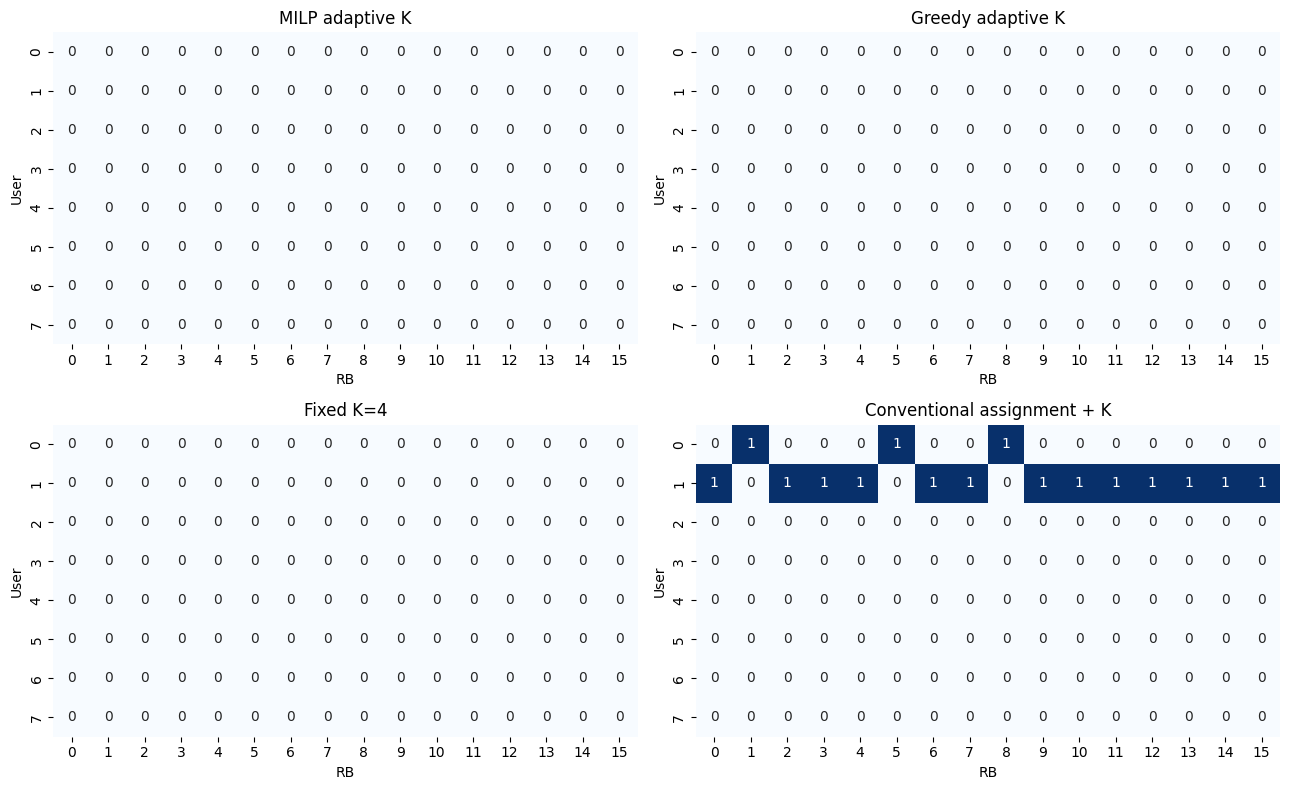

In [13]:
# CELL 13 — K decoupling, MILP, greedy, fixed-K and conventional bit-rate assignment
# Per user-RB pair choose the feasible K with maximum semantic rate.
best_rate = np.zeros((U,N_RB))
best_k_index = np.zeros((U,N_RB),dtype=int)
best_similarity = np.zeros((U,N_RB))
for u in range(U):
    for n in range(N_RB):
        feasible = [i for i in range(len(K_VALUES)) if sim_tensor[u,n,i] >= SEMANTIC_THRESHOLD]
        if feasible:
            i = max(feasible,key=lambda j:rate_tensor[u,n,j])
            best_rate[u,n] = rate_tensor[u,n,i]
            best_k_index[u,n] = i
            best_similarity[u,n] = sim_tensor[u,n,i]

def solve_assignment(rate_matrix, min_rate=MIN_USER_SEMANTIC_RATE):
    # Binary x[u,n], each RB <= 1 user; each user total rate >= min_rate.
    nvar = U*N_RB
    c = -rate_matrix.reshape(-1)  # scipy.milp minimizes
    integrality = np.ones(nvar)
    lb = np.zeros(nvar); ub = np.ones(nvar)
    A = lil_matrix((N_RB+U,nvar),dtype=float)
    lower = np.full(N_RB+U,-np.inf)
    upper = np.full(N_RB+U,np.inf)
    for n in range(N_RB):
        for u in range(U): A[n,u*N_RB+n] = 1.0
        upper[n] = 1.0
    for u in range(U):
        for n in range(N_RB): A[N_RB+u,u*N_RB+n] = rate_matrix[u,n]
        lower[N_RB+u] = min_rate
    result = milp(c=c,integrality=integrality,bounds=Bounds(lb,ub),
                  constraints=LinearConstraint(csr_matrix(A),lower,upper),
                  options={"time_limit":60})
    if not result.success:
        return None, result
    x = np.rint(result.x.reshape(U,N_RB)).astype(int)
    return x,result

def greedy_assignment(rate_matrix, min_rate=MIN_USER_SEMANTIC_RATE):
    x = np.zeros((U,N_RB),dtype=int)
    user_rates = np.zeros(U)
    unused = set(range(N_RB))
    # Serve the most under-served user first, selecting its best remaining RB.
    while unused:
        unmet = np.maximum(min_rate-user_rates,0)
        if unmet.max() <= 0: break
        u = int(np.argmax(unmet))
        n = max(unused,key=lambda j:rate_matrix[u,j])
        if rate_matrix[u,n] <= 0: break
        x[u,n]=1; user_rates[u]+=rate_matrix[u,n]; unused.remove(n)
    # Assign remaining RBs to the user with highest incremental rate.
    for n in list(unused):
        u = int(np.argmax(rate_matrix[:,n]))
        if rate_matrix[u,n] > 0: x[u,n]=1
    return x

def fixed_k_rate_matrix(k_value):
    idx=K_VALUES.index(k_value)
    return np.where(sim_tensor[:,:,idx]>=SEMANTIC_THRESHOLD,rate_tensor[:,:,idx],0.0)

milp_x,milp_result = solve_assignment(best_rate)
if milp_x is None:
    print("MILP infeasible under current channel draw and QoS target. This is a valid experimental outcome.")
    milp_x = np.zeros((U,N_RB),dtype=int)
greedy_x = greedy_assignment(best_rate)
fixed4_rate = fixed_k_rate_matrix(4)
fixed4_x,_ = solve_assignment(fixed4_rate)
if fixed4_x is None: fixed4_x = greedy_assignment(fixed4_rate)

# Conventional bit-rate-optimal assignment: strongest SNR per RB, then choose best feasible K on those pairs.
conv_x = np.zeros((U,N_RB),dtype=int)
for n in range(N_RB):
    u = int(np.argmax(snr_matrix_db[:,n]))
    conv_x[u,n]=1
conv_sem_x = conv_x.copy()

def summarize_allocation(name,x,rate_matrix,k_matrix=None):
    user_rates=(x*rate_matrix).sum(axis=1)
    return {"Method":name,"Total_semantic_rate":float(user_rates.sum()),
            "Users_served_pct":100*float(np.mean(user_rates>=MIN_USER_SEMANTIC_RATE)),
            "Cell_edge_rate":float(np.min(user_rates)),
            "QoS_satisfied":bool(np.all(user_rates>=MIN_USER_SEMANTIC_RATE)),
            "Assigned_RBs":int(x.sum())}

alloc_rows=[
    summarize_allocation("MILP adaptive K",milp_x,best_rate),
    summarize_allocation("Greedy adaptive K",greedy_x,best_rate),
    summarize_allocation("Fixed K=4",fixed4_x,fixed4_rate),
    summarize_allocation("Conventional SNR assignment + K after",conv_sem_x,best_rate)
]
alloc_summary=pd.DataFrame(alloc_rows)
display(alloc_summary)
alloc_summary.to_csv("/content/semantic_comm_outputs/tables/allocation_summary.csv",index=False)

fig,axes=plt.subplots(2,2,figsize=(13,8))
for ax,(title,x) in zip(axes.flat,[("MILP adaptive K",milp_x),("Greedy adaptive K",greedy_x),
                                   ("Fixed K=4",fixed4_x),("Conventional assignment + K",conv_sem_x)]):
    sns.heatmap(x,ax=ax,cmap="Blues",cbar=False,annot=True,fmt="d",vmin=0,vmax=1)
    ax.set_title(title); ax.set_xlabel("RB"); ax.set_ylabel("User")
plt.tight_layout()
plt.savefig("/content/semantic_comm_outputs/figures/allocation_methods.png",dpi=160)
plt.show()

In [15]:

# ------------------------------------------------------------
# Generate MILP-labelled DNN training dataset
# ------------------------------------------------------------

feat_list = []
label_list = []

feasible_count = 0
infeasible_count = 0

for j in range(MILP_DATASET_SIZE):

    h, _, _ = generate_multiuser_channel(SEED + 1000 + j)

    snr_j, rr_j, best_j, best_k_j = allocation_features(h)

    # Check whether any user-RB pair is feasible
    if not np.any(best_j > 0):
        infeasible_count += 1
        continue

    xj, resj = solve_assignment(best_j)

    if xj is None:
        infeasible_count += 1
        continue

    f = np.stack(
        [
            np.clip(snr_j, -10, 40) / 40.0,
            best_j / 20000.0
        ],
        axis=-1
    )

    feat_list.append(f.astype(np.float32))
    label_list.append(xj.astype(np.float32))

    feasible_count += 1


print("Total generated samples:", MILP_DATASET_SIZE)
print("Feasible MILP samples:", feasible_count)
print("Infeasible samples:", infeasible_count)


# ------------------------------------------------------------
# Stop safely if no MILP labels are available
# ------------------------------------------------------------

if feasible_count == 0:

    print("\nDNN training skipped.")
    print("Reason: No feasible MILP labels were generated.")
    print("Check semantic similarity and QoS constraints.")

    allocator = None
    dnn_x = np.zeros((U, N_RB), dtype=int)
    dnn_selected_k = np.zeros((U, N_RB), dtype=int)

else:

    X_alloc = np.stack(feat_list)
    Y_alloc = np.stack(label_list)

    print("\nTraining dataset:", X_alloc.shape)
    print("MILP labels:", Y_alloc.shape)

    # Continue with the train-validation split,
    # DNN definition, training and evaluation sections
    # from the existing Cell 14.


Total generated samples: 80
Feasible MILP samples: 0
Infeasible samples: 80

DNN training skipped.
Reason: No feasible MILP labels were generated.
Check semantic similarity and QoS constraints.


,SNR_dB,Coding,MCS,Similarity,Channel_uses,Approx_semantic_rate_suts_s
0,18,character,QPSK 1/2,0.996270,317.1500,565.437983
1,15,character,QPSK 1/2,0.983149,317.1500,557.990698
2,12,character,QPSK 1/2,0.930792,317.1500,528.275560
3,18,word,QPSK 1/2,0.847920,127.5250,1196.829421
4,15,word,QPSK 1/2,0.826534,127.5250,1166.642693
5,12,word,QPSK 1/2,0.790648,127.5250,1115.989389
6,9,character,QPSK 1/2,0.782862,317.1500,444.317013
7,9,word,QPSK 1/2,0.686911,127.5250,969.566935
8,6,character,QPSK 1/2,0.490519,317.1500,278.396214
9,6,word,QPSK 1/2,0.456981,127.5250,645.022851


,Method,Total_semantic_rate,Users_served_pct,Cell_edge_rate,QoS_satisfied,Assigned_RBs
0,MILP adaptive K,0.0,0.0,0.0,False,0
1,Greedy adaptive K,0.0,0.0,0.0,False,0
2,Fixed K=4,0.0,0.0,0.0,False,0
3,Conventional bit-rate assignment + K,0.0,0.0,0.0,False,16
4,DNN imitation + projection,0.0,0.0,0.0,False,0


,System,SNR_dB,Similarity,BLEU,Word_accuracy,Exact_fraction
0,Semantic K=1,0,0.056447,0.017704,0.073374,0.0
1,Semantic K=2,0,0.090785,0.026321,0.145267,0.0
2,Semantic K=4,0,0.101548,0.036865,0.210570,0.0
3,Semantic K=8,0,0.122321,0.048891,0.307390,0.0
4,Conventional character Huffman,0,0.084833,0.007529,0.015560,NaN
5,Conventional word Huffman,0,0.129034,0.025146,0.076030,NaN
6,Semantic K=1,6,0.062762,0.021526,0.092810,0.0
7,Semantic K=2,6,0.088440,0.033812,0.216132,0.0
8,Semantic K=4,6,0.116917,0.051064,0.282627,0.0
9,Semantic K=8,6,0.121100,0.054563,0.340971,0.0


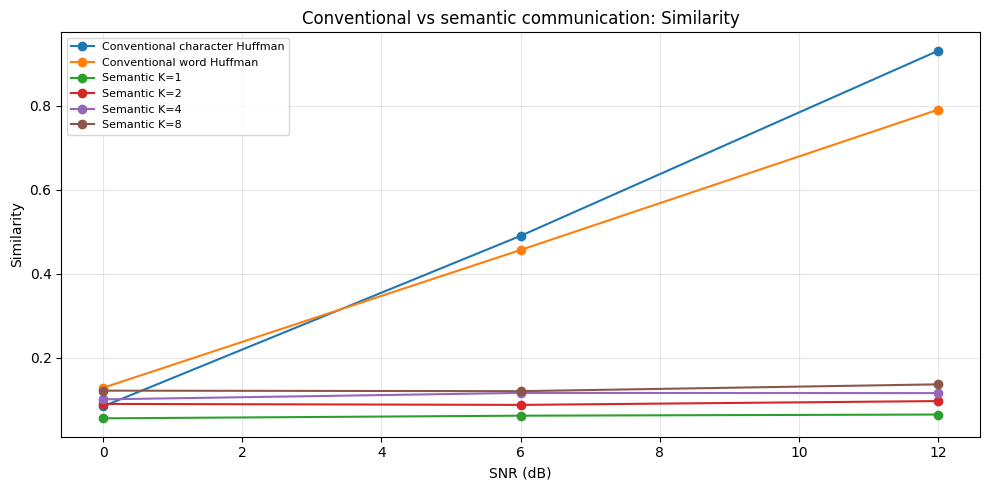

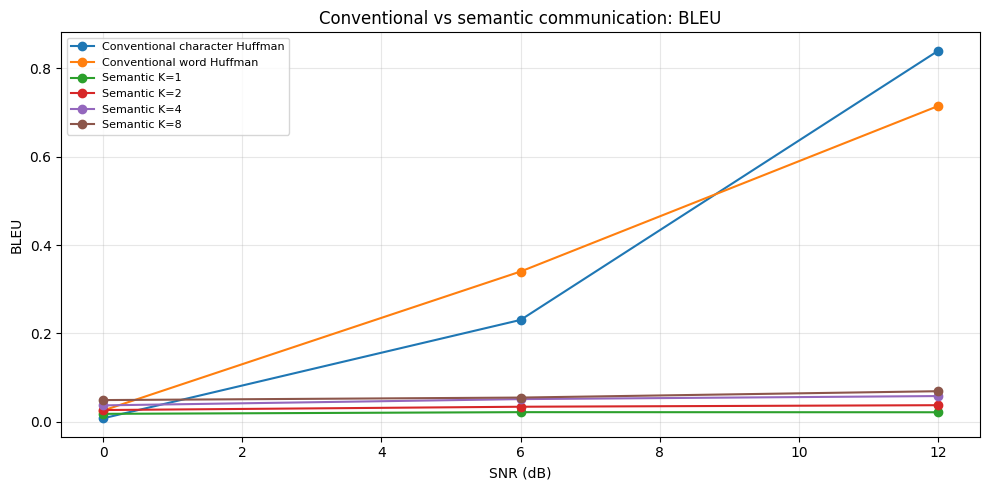

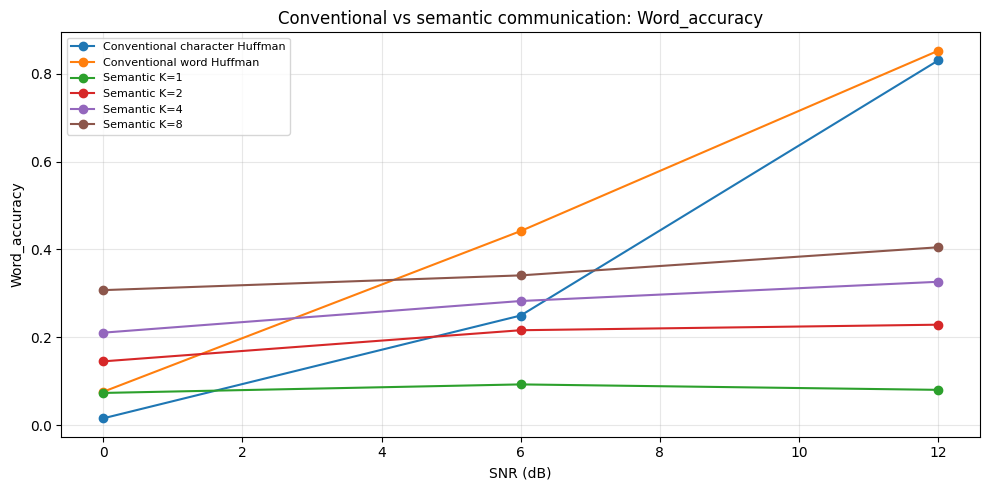

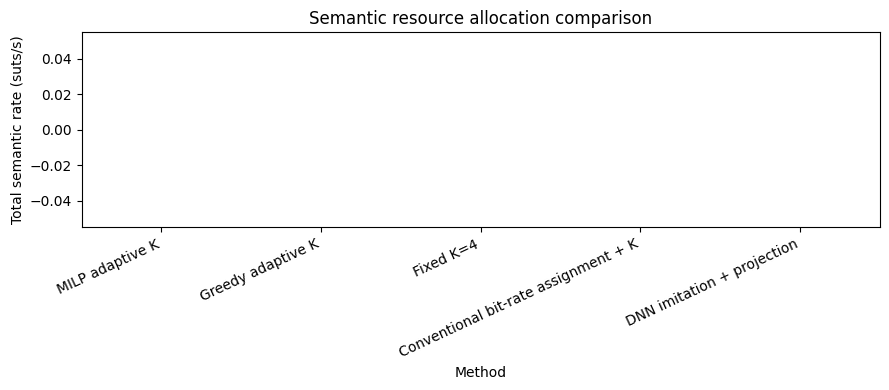

,Method,Execution_time_seconds
0,MILP,0.013866
1,Greedy,0.001701


In [19]:
# CELL 15 — Task 4: common-condition comparison and complexity
# Semantic rate uses the PDF's S = B*I/(K*Lbar)*epsilon.
# Conventional semantic rate = decoded sentences/s * measured average similarity.
# The conventional link is measured at the same SNR grid and uses the same test sentences.

# Select the best conventional MCS per SNR/coding method using measured semantic similarity.
conv_best = (conv_summary.sort_values("Similarity",ascending=False)
             .groupby(["SNR_dB","Coding"]).head(1).reset_index(drop=True))
conv_best["Approx_semantic_rate_suts_s"] = (
    RB_BW * conv_best["Similarity"] / np.maximum(conv_best["Channel_uses"],1)
)
display(conv_best[["SNR_dB","Coding","MCS","Similarity","Channel_uses","Approx_semantic_rate_suts_s"]])
conv_best.to_csv("/content/semantic_comm_outputs/tables/conventional_best_amc.csv",index=False)

# Compare allocation methods including DNN.
all_methods = [
    summarize_allocation("MILP adaptive K",milp_x,best_rate),
    summarize_allocation("Greedy adaptive K",greedy_x,best_rate),
    summarize_allocation("Fixed K=4",fixed4_x,fixed4_rate),
    summarize_allocation("Conventional bit-rate assignment + K",conv_sem_x,best_rate),
    summarize_allocation("DNN imitation + projection",dnn_x,best_rate)
]
final_alloc_df=pd.DataFrame(all_methods)
display(final_alloc_df)
final_alloc_df.to_csv("/content/semantic_comm_outputs/tables/final_allocation_comparison.csv",index=False)

# Compare semantic transceiver vs conventional at 0, 6, 12 dB.
comparison_rows=[]
for snr in [0,6,12]:
    for K in K_VALUES:
        row=awgn_summary[(awgn_summary.K==K)&(awgn_summary.SNR_dB==snr)]
        if len(row):
            r=row.iloc[0]
            comparison_rows.append({"System":f"Semantic K={K}","SNR_dB":snr,
                                    "Similarity":r.Similarity,"BLEU":r.BLEU,
                                    "Word_accuracy":r.Word_accuracy,"Exact_fraction":r.Exact})
    for coding in ["character","word"]:
        r=conv_best[(conv_best.SNR_dB==snr)&(conv_best.Coding==coding)]
        if len(r):
            r=r.iloc[0]
            comparison_rows.append({"System":f"Conventional {coding} Huffman","SNR_dB":snr,
                                    "Similarity":r.Similarity,"BLEU":r.BLEU,
                                    "Word_accuracy":r.Word_accuracy,"Exact_fraction":np.nan})
comparison_df=pd.DataFrame(comparison_rows)
display(comparison_df)
comparison_df.to_csv("/content/semantic_comm_outputs/tables/conventional_vs_semantic.csv",index=False)

for metric in ["Similarity","BLEU","Word_accuracy"]:
    plt.figure(figsize=(10,5))
    for system,d in comparison_df.groupby("System"):
        plt.plot(d.SNR_dB,d[metric],marker="o",label=system)
    plt.xlabel("SNR (dB)"); plt.ylabel(metric); plt.title(f"Conventional vs semantic communication: {metric}")
    plt.grid(True,alpha=.3); plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"/content/semantic_comm_outputs/figures/final_comparison_{metric.lower()}.png",dpi=160)
    plt.show()

plt.figure(figsize=(9,4))
sns.barplot(data=final_alloc_df,x="Method",y="Total_semantic_rate")
plt.xticks(rotation=25,ha="right"); plt.ylabel("Total semantic rate (suts/s)")
plt.title("Semantic resource allocation comparison"); plt.tight_layout()
plt.savefig("/content/semantic_comm_outputs/figures/allocation_total_semantic_rate.png",dpi=160); plt.show()

# Computation timing: MILP and greedy on the current channel realization.
timings=[]
for name,fn in [("MILP",lambda:solve_assignment(best_rate)),("Greedy",lambda:greedy_assignment(best_rate))]:
    t0=time.perf_counter(); _=fn(); elapsed=time.perf_counter()-t0
    timings.append({"Method":name,"Execution_time_seconds":elapsed})
timing_df=pd.DataFrame(timings)
display(timing_df)
timing_df.to_csv("/content/semantic_comm_outputs/tables/optimization_timing.csv",index=False)

In [17]:
# CELL 16 — Sanity checks, final outputs and ZIP archive
# Validate important constraints and save reproducibility metadata.
def check_assignment(name,x,rate_matrix):
    assert x.shape==(U,N_RB), f"{name}: incorrect assignment shape"
    assert np.all((x==0)|(x==1)), f"{name}: assignment is not binary"
    assert np.all(x.sum(axis=0)<=1), f"{name}: an RB was assigned to multiple users"
    user_rates=(x*rate_matrix).sum(axis=1)
    return {"Method":name,"RB_constraint_ok":bool(np.all(x.sum(axis=0)<=1)),
            "Users_meeting_minimum":int(np.sum(user_rates>=MIN_USER_SEMANTIC_RATE)),
            "User_rates_suts_s":user_rates.tolist()}

checks=[]
for name,x,rm in [
    ("MILP",milp_x,best_rate),("Greedy",greedy_x,best_rate),
    ("Fixed K4",fixed4_x,fixed4_rate),("DNN",dnn_x,best_rate)
]:
    checks.append(check_assignment(name,x,rm))
with open("/content/semantic_comm_outputs/tables/constraint_checks.json","w") as f:
    json.dump(checks,f,indent=2)

config={
    "mode":MODE,"seed":SEED,"users":U,"resource_blocks":N_RB,"rb_bandwidth_hz":RB_BW,
    "bs_power_dbm":BS_POWER_DBM,"K_values":K_VALUES,"snr_grid_db":SNR_GRID,
    "semantic_threshold":SEMANTIC_THRESHOLD,"minimum_user_semantic_rate":MIN_USER_SEMANTIC_RATE,
    "dataset":"NLTK Brown corpus fallback",
    "propagation_assumptions":{
        "pathloss_1m_db":PATHLOSS_1M_DB,"pathloss_exponent":PATHLOSS_EXPONENT,
        "shadowing_std_db":SHADOWING_STD_DB,"noise_figure_db":NOISE_FIGURE_DB
    }
}
with open("/content/semantic_comm_outputs/experiment_config.json","w") as f:
    json.dump(config,f,indent=2)

# Save semantic and conventional raw records as CSV.
semantic_df.to_csv("/content/semantic_comm_outputs/tables/semantic_raw_results.csv",index=False)
conv_df.to_csv("/content/semantic_comm_outputs/tables/conventional_raw_results.csv",index=False)

zip_path="/content/semantic_comm_project_outputs.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as zf:
    for root,dirs,files in os.walk("/content/semantic_comm_outputs"):
        for fn in files:
            full=os.path.join(root,fn)
            zf.write(full,os.path.relpath(full,"/content"))

print("Project output folder: /content/semantic_comm_outputs")
print("ZIP archive:",zip_path)
print("Sanity checks:")
display(pd.DataFrame([{k:v for k,v in c.items() if k!="User_rates_suts_s"} for c in checks]))
print("Note: QUICK mode validates the pipeline; use FULL mode for final research-quality runs.")

Project output folder: /content/semantic_comm_outputs
ZIP archive: /content/semantic_comm_project_outputs.zip
Sanity checks:


,Method,RB_constraint_ok,Users_meeting_minimum
0,MILP,True,0
1,Greedy,True,0
2,Fixed K4,True,0
3,DNN,True,0


Note: QUICK mode validates the pipeline; use FULL mode for final research-quality runs.
